In [ ]:
import pandas as pd
df = pd.read_csv("../data/Pasion et al dataset.csv")
# convert US units to metric, as in the paper
df["Altitude"] = (df["Altitude"] * 0.3048).round(1)            # feet -> m
df["Wind.Speed"] = (df["Wind.Speed"] * 1.609).round(1)         # mph -> km/h
df["Visibility"] = (df["Visibility"] * 1.609).round(1)         # miles -> km
df["Cloud.Ceiling"] = (df["Cloud.Ceiling"] * 0.03048).round(1) # 100 ft -> km

In [2]:
#Field 6: Content
print(df.shape)
print(df.dtypes)

(21045, 17)
Location          object
Date               int64
Time               int64
Latitude         float64
Longitude        float64
Altitude         float64
YRMODAHRMI       float64
Month              int64
Hour               int64
Season            object
Humidity         float64
AmbientTemp      float64
PolyPwr          float64
Wind.Speed       float64
Visibility       float64
Pressure         float64
Cloud.Ceiling    float64
dtype: object


In [3]:
cutoff = df["PolyPwr"].median()
# df["good_hour"] = (df["PolyPwr"] >= cutoff)
df["good_hour"] = (df["PolyPwr"] >= cutoff).astype(int)
print(cutoff)

# share of the 50 W panel rating
print(cutoff / 50)

print(df["good_hour"].value_counts())
print(df["PolyPwr"].max(), (df["PolyPwr"] >= 25).mean())

# first and last measurement date per site
dates = pd.to_datetime(df["Date"], format="%Y%m%d")
print(dates.groupby(df["Location"]).agg(["min", "max"]))


13.7987
0.275974
good_hour
1    10523
0    10522
Name: count, dtype: int64
34.28502 0.0305535756711808
                   min        max
Location                         
Camp Murray 2017-12-03 2018-10-02
Grissom     2017-11-07 2018-10-04
Hill Weber  2017-06-19 2018-10-04
JDMT        2017-05-23 2018-05-24
Kahului     2017-11-03 2018-06-13
MNANG       2017-11-09 2018-10-02
Malmstrom   2017-10-31 2018-09-30
March AFB   2017-07-06 2018-10-02
Offutt      2018-04-01 2018-09-27
Peterson    2017-06-23 2018-09-27
Travis      2017-06-09 2018-10-03
USAFA       2017-05-25 2018-10-01


0 0
3656
5.756291028446389
        AmbientTemp      Humidity  Cloud.Ceiling    Visibility
count  21045.000000  21045.000000   21045.000000  21045.000000
mean      29.285117     37.121941      15.721853     15.616531
std       12.366820     23.823011       9.199328      2.178584
min      -19.981770      0.000000       0.000000      0.000000
25%       21.915280     17.529300       4.300000     16.100000
50%       30.289150     33.123780      22.000000     16.100000
75%       37.474670     52.593990      22.000000     16.100000
max       65.738370     99.987790      22.000000     16.100000
9.1
52
20993 {1: 10506, 0: 10487}


array([[<Axes: title={'center': 'AmbientTemp'}>,
        <Axes: title={'center': 'Humidity'}>],
       [<Axes: title={'center': 'Cloud.Ceiling'}>,
        <Axes: title={'center': 'Visibility'}>]], dtype=object)

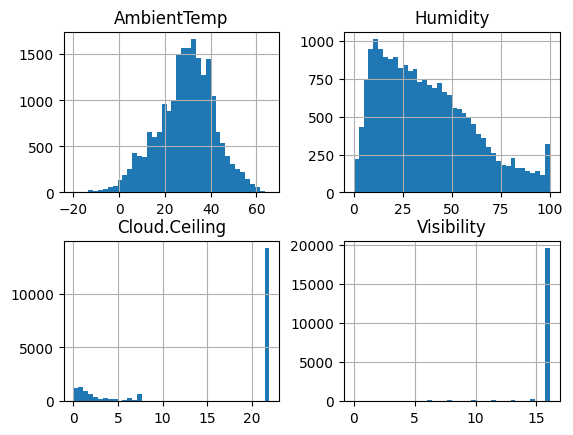

In [4]:
# Field 7: Quality
inputs = ["Latitude", "Longitude", "Altitude", "Month", "Hour", "Season",
          "Humidity", "AmbientTemp", "Wind.Speed", "Visibility",
          "Pressure", "Cloud.Ceiling"]
print(df.isna().sum().sum(), df.duplicated(subset=inputs).sum())
print(df.groupby(["Location", "Date"]).ngroups)
#The amount of measurements per site and day
print(len(df) / df.groupby(["Location", "Date"]).ngroups)

print(df[["AmbientTemp", "Humidity", "Cloud.Ceiling", "Visibility"]].describe())
real_clouds = df[df["Cloud.Ceiling"] < 22]
print(real_clouds["Cloud.Ceiling"].max())
print((df["Humidity"] == 0).sum())
df = df[df["Humidity"] != 0]
print(len(df), df["good_hour"].value_counts().to_dict())

# Figure for field 7
df[["AmbientTemp", "Humidity", "Cloud.Ceiling", "Visibility"]].hist(bins=40)


AmbientTemp {0: 22.8, 1: 35.7}
Humidity {0: 45.6, 1: 28.9}
Hour {0: 12.5, 1: 12.8}
good_hour
0    0.500620
1    0.852465
Name: Cloud.Ceiling, dtype: float64


array([<Axes: title={'center': 'AmbientTemp'}, xlabel='good_hour'>,
       <Axes: title={'center': 'Humidity'}, xlabel='good_hour'>],
      dtype=object)

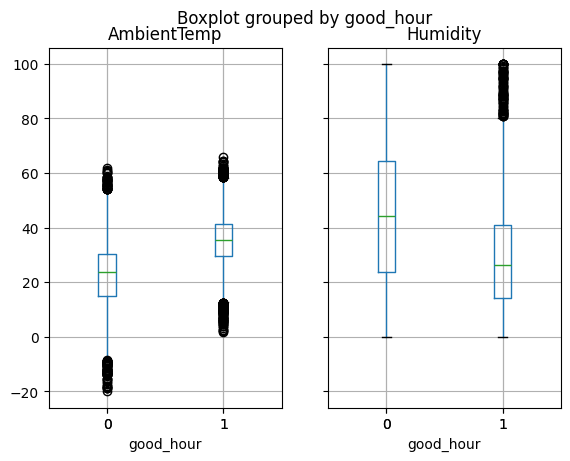

In [5]:
# Field 8: Signal
for col in ["AmbientTemp", "Humidity", "Hour"]:
    print(col, df.groupby("good_hour")[col].mean().round(1).to_dict())
print((df["Cloud.Ceiling"] == 22.0).groupby(df["good_hour"]).mean())

# Figure for field 8
df.boxplot(column=["AmbientTemp", "Humidity"], by="good_hour")



In [6]:
#Baseline
print(df["good_hour"].value_counts(normalize=True).max())

0.5004525317963131
